# Phase 2, Step 2.7: Faithfulness test (Grad-CAM region vs random region)
**Run settings:** GPU T4, Internet On, *Save and Run All*. Expected run time: roughly 40 to 90 minutes. Progress is saved per condition, so a crash can resume.

**Inputs (each file once):** best.pt + config.json + threshold.json | faces_manifest.csv + manifest_meta.json | faces_manifest_B/D.csv + compressed crops | clean crops | Step 2.5 output (predictions_A..D.csv, eval_meta.json) | **Step 2.6 output (cams_A..D.npz, cam_face_stats.csv)**.

**Definition (frozen before looking at results):**
- p_pred = probability of the class the model predicted (the class Grad-CAM explained; `target` from cams_*.npz).
- Mask the top k% Grad-CAM cells of the 10x10 map (k = 20 primary; 10 and 30 as sensitivity), fill = 0 in normalised input space (mid-grey).
- delta_cam = p_pred(original) - p_pred(masked). delta_rand = mean over R random masks with exactly the same number of cells.
- **Faithfulness Score = delta_cam - delta_rand.** Deletion check: masking the LOWEST k% cells (delta_low) should hurt less than the top k%.
- Second fill (blur) on a fixed subset. Bootstrap CIs resample VIDEOS. Report accuracy next to every score.

In [1]:
import os, sys, json, time, hashlib, zipfile, copy
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import cv2
from PIL import Image

try:
    import timm
except ImportError:
    os.system("pip install -q --no-deps timm huggingface_hub safetensors")
    import timm

REPO_URL = "https://github.com/Mugdha-Naik/deepfake-detector-project.git"
REPO_DIR = "/kaggle/working/repo"
if not os.path.exists(REPO_DIR):
    os.system(f"git clone {REPO_URL} {REPO_DIR}")
else:
    os.system(f"cd {REPO_DIR} && git pull")
sys.path.append(REPO_DIR)
import dfx_model, dfx_data

INPUT_ROOT = "/kaggle/input"
OUT = "/kaggle/working/p2_7"
CROPS = "/kaggle/working/crops"
os.makedirs(OUT, exist_ok=True); os.makedirs(CROPS, exist_ok=True)

BATCH_SIZE, NUM_WORKERS = 32, 2
SEED = 2026

def find_one(name, roots):
    for root in roots:
        matches = [os.path.join(d, name) for d, _, fs in os.walk(root) if name in fs]
        if len(matches) == 1:
            return matches[0]
        if len(matches) > 1:
            raise RuntimeError(f"{name}: {len(matches)} copies under {root}. Attach only one:\n" + "\n".join(matches))
    raise FileNotFoundError(f"{name} not found under {roots}")

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "Set the Accelerator to GPU T4."
print("device:", torch.cuda.get_device_name(0), "| torch", torch.__version__, "| timm", timm.__version__)
import torch.nn.functional as F
from torchvision.transforms import functional as TF
KS = (10, 20, 30)          # percent of cells masked; 20 is primary
K_PRIMARY = 20
R = 5                      # random masks per face per k (plan: 5 to 10)
BLUR_SUBSET = 1000         # faces per condition for the second fill
CONF_MIN = 0.8             # "confident" = p_pred >= 0.8 (fixed now, before results)
N_BOOT = 1000

Cloning into '/kaggle/working/repo'...


device: Tesla T4 | torch 2.11.0+cu130 | timm 1.0.30


In [2]:
# ============================================================
# LOAD MODEL, FROZEN THRESHOLD, MANIFEST (same integrity checks as Step 2.5)
# ============================================================

best_pt = find_one("best.pt", [INPUT_ROOT])
config_json = find_one("config.json", [INPUT_ROOT])
thr_json = find_one("threshold.json", [INPUT_ROOT])
config = json.load(open(config_json)); thr_info = json.load(open(thr_json))
assert not config.get("debug"), "config.json comes from a DEBUG run."
assert config["train_faces"] > 5000, "not the full training run"
THRESHOLD = float(thr_info["value"])
assert abs(THRESHOLD - 0.2217) < 5e-4, f"threshold {THRESHOLD} is not the frozen 0.2217"
MEAN, STD, SIZE = tuple(config["mean"]), tuple(config["std"]), dfx_model.INPUT_SIZE

manifest_csv = find_one("faces_manifest.csv", [INPUT_ROOT, REPO_DIR])
meta = json.load(open(find_one("manifest_meta.json", [INPUT_ROOT, REPO_DIR])))
assert sha256(manifest_csv) == meta["manifest_sha256"], "manifest does not match manifest_meta.json"
assert config["manifest_sha256"] == meta["manifest_sha256"], "model trained on a different manifest"

model, info = dfx_model.build_xception(pretrained=False)
dfx_model.load_checkpoint(model, best_pt, map_location=device)
model = model.to(device).eval()
for p in model.parameters():
    p.requires_grad_(False)

eval_meta = json.load(open(find_one("eval_meta.json", [INPUT_ROOT, REPO_DIR])))
assert eval_meta["model_sha256"] == sha256(best_pt), "Step 2.5 used a different checkpoint than the one attached now"
assert abs(eval_meta["threshold"] - THRESHOLD) < 1e-9, "Step 2.5 used a different threshold"
print(f"model OK | epoch {config['best_epoch']} | threshold {THRESHOLD:.4f} | manifest {meta['manifest_sha256'][:8]}")

model OK | epoch 8 | threshold 0.2217 | manifest 80eae250


In [3]:
# ============================================================
# LOCATE CROPS (folder or zip) AND BUILD CONDITION TABLES A, B, C, D
# ============================================================
def unzip_if_needed(zip_name):
    """If <zip_name> is attached as a zip, extract once to /kaggle/working/crops/<stem>. Returns a search base."""
    zips = [os.path.join(d, zip_name) for d, _, fs in os.walk(INPUT_ROOT) if zip_name in fs]
    if not zips:
        return None
    assert len(zips) == 1, f"{zip_name}: {len(zips)} copies attached: {zips}"
    dest = os.path.join(CROPS, zip_name.replace(".zip", ""))
    if not os.path.exists(os.path.join(dest, ".done")):
        t = time.time(); os.makedirs(dest, exist_ok=True)
        with zipfile.ZipFile(zips[0]) as z:
            z.extractall(dest)
        open(os.path.join(dest, ".done"), "w").close()
        print(f"unzipped {zip_name} in {time.time() - t:.0f}s")
    return dest

def find_crop_root(df, bases, label):
    sample = df["face_rel"].sample(min(12, len(df)), random_state=0).tolist()
    for base in bases:
        if base is None:
            continue
        for d, _, _ in os.walk(base):
            if all(os.path.exists(os.path.join(d, r)) for r in sample):
                print(f"{label}: crops under {d}")
                return d
    raise FileNotFoundError(f"{label}: no folder contains the sample crops (face_rel). Check the attached datasets.")

m = pd.read_csv(manifest_csv)
assert {"test_A", "test_C"} <= set(m["role"])
clean_df = {"A": m[m["role"] == "test_A"].reset_index(drop=True), "C": m[m["role"] == "test_C"].reset_index(drop=True)}
clean_zip = unzip_if_needed("step5_faces.zip")
comp_zip = unzip_if_needed("compressed_faces.zip")
clean_root = find_crop_root(pd.concat(clean_df.values()),
                            ["/kaggle/input/notebooks/mugdhanaik/step5-regenerate/step5_faces", clean_zip, INPUT_ROOT],
                            "clean crops")

cond = {}
for k in "AC":
    cond[k] = {"df": clean_df[k], "root": clean_root, "name": {"A": "A: FF++ test (clean)", "C": "C: Celeb-DF test (clean)"}[k]}
for k, c in (("B", "A"), ("D", "C")):
    dfk = pd.read_csv(find_one(f"faces_manifest_{k}.csv", [INPUT_ROOT, REPO_DIR]))
    assert len(dfk) == len(cond[c]["df"]), f"{k}: row count differs from {c}"
    assert set(dfk["pair_id"]) <= set(cond[c]["df"]["face_id"]), f"{k}: pair_id does not point to clean faces"
    cond[k] = {"df": dfk, "root": None, "name": {"B": "B: FF++ test (compressed)", "D": "D: Celeb-DF test (compressed)"}[k]}
comp_root = find_crop_root(pd.concat([cond["B"]["df"], cond["D"]["df"]]), [comp_zip, INPUT_ROOT], "compressed crops")
cond["B"]["root"] = cond["D"]["root"] = comp_root

pred25 = {}
for k in "ABCD":
    pr = pd.read_csv(find_one(f"predictions_{k}.csv", [INPUT_ROOT, REPO_DIR]))
    assert set(pr["face_id"]) == set(cond[k]["df"]["face_id"]), f"{k}: Step 2.5 predictions do not match this manifest"
    pred25[k] = pr.set_index("face_id")
rows = [{"cond": k, "faces": len(cond[k]["df"]), "videos": cond[k]["df"]["video_id"].nunique()} for k in "ABCD"]
print(pd.DataFrame(rows).to_string(index=False))

clean crops: crops under /kaggle/input/notebooks/mugdhanaik/step5-regenerate/step5_faces
compressed crops: crops under /kaggle/input/notebooks/mugdhanaik/phase2-step2/compressed_faces
cond  faces  videos
   A   5883     198
   B   5883     198
   C   8763     300
   D   8763     300


In [4]:
# ============================================================
# LOAD STEP 2.6 MAPS AND CHECK THEY BELONG TO THIS MODEL / MANIFEST
# ============================================================
g_meta = json.load(open(find_one("gradcam_meta.json", [INPUT_ROOT, REPO_DIR])))
assert g_meta["model_sha256"] == sha256(best_pt), "Step 2.6 maps were made with a different checkpoint"
assert g_meta["manifest_sha256"] == meta["manifest_sha256"], "Step 2.6 maps were made with a different manifest"
assert abs(g_meta["threshold"] - THRESHOLD) < 1e-9
cams = {}
for k in "ABCD":
    z = np.load(find_one(f"cams_{k}.npz", [INPUT_ROOT]), allow_pickle=True)
    ids = [str(i) for i in z["face_id"]]
    assert set(ids) == set(cond[k]["df"]["face_id"].astype(str)), f"{k}: maps do not match the manifest"
    cams[k] = {"idx": {f: i for i, f in enumerate(ids)}, "cam": z["cam"], "target": z["target"], "prob": z["prob"]}
    print(f"{k}: {len(ids)} maps loaded")

A: 5883 maps loaded
B: 5883 maps loaded
C: 8763 maps loaded
D: 8763 maps loaded


In [5]:
# ============================================================
# MASKING + FAITHFULNESS FUNCTIONS
# ============================================================
GRID = 10
def cells_to_mask(sel):
    """sel: bool (B,100) -> float mask (B,1,299,299) by nearest-neighbour upsampling of the 10x10 grid."""
    m = sel.view(-1, 1, GRID, GRID).float()
    return F.interpolate(m, size=(SIZE, SIZE), mode="nearest")

def top_cells(cam, n, lowest=False):
    """cam: (B,10,10). Boolean (B,100) selecting the n highest (or lowest) cells; ties broken by cell order."""
    flat = cam.reshape(len(cam), -1)
    order = torch.argsort(flat, dim=1, descending=not lowest, stable=True)[:, :n]
    sel = torch.zeros_like(flat, dtype=torch.bool); sel.scatter_(1, order, True)
    return sel

def random_cells(B, n, gen):
    r = torch.rand(B, GRID * GRID, generator=gen, device=device)
    order = torch.argsort(r, dim=1)[:, :n]
    sel = torch.zeros(B, GRID * GRID, dtype=torch.bool, device=device); sel.scatter_(1, order, True)
    return sel

@torch.no_grad()
def p_pred(x, tgt):
    """Probability of the explained (predicted) class; autocast like Step 2.5. tgt in {-1,+1} -> FAKE / REAL."""
    with torch.autocast("cuda", dtype=torch.float16):
        p = torch.sigmoid(model(x).float().reshape(-1))
    return torch.where(tgt > 0, p, 1 - p)

def apply_mask(x, sel, fill):
    m = cells_to_mask(sel)
    if fill == "zero":                      # 0 in normalised space = mid-grey (mean 0.5 / std 0.5)
        return x * (1 - m)
    if fill == "blur":
        return x * (1 - m) + TF.gaussian_blur(x, kernel_size=61, sigma=20.0) * m
    raise ValueError(fill)

def faithfulness_batch(x, cam, tgt, fill, gen):
    out = {"p0": p_pred(x, tgt)}
    for k in KS:
        n = int(round(GRID * GRID * k / 100))
        d_cam = out["p0"] - p_pred(apply_mask(x, top_cells(cam, n), fill), tgt)
        d_low = out["p0"] - p_pred(apply_mask(x, top_cells(cam, n, lowest=True), fill), tgt)
        d_rand = torch.stack([out["p0"] - p_pred(apply_mask(x, random_cells(len(x), n, gen), fill), tgt) for _ in range(R)])
        out[f"d_cam_{k}"], out[f"d_low_{k}"] = d_cam, d_low
        out[f"d_rand_{k}"], out[f"d_rand_sd_{k}"] = d_rand.mean(0), d_rand.std(0)
        out[f"faith_{k}"] = d_cam - d_rand.mean(0)
    return {kk: v.float().cpu().numpy() for kk, v in out.items()}

def run_faith(k, fill, df, tag):
    path = os.path.join(OUT, f"faithfulness_{k}{tag}.csv")
    if os.path.exists(path):
        print(f"{k}{tag}: found {path}, skipping (delete to recompute)"); return pd.read_csv(path)
    gen = torch.Generator(device=device); gen.manual_seed(SEED + "ABCD".index(k) + (100 if fill == "blur" else 0))
    t0, rows = time.time(), []
    for x, y, fid in loader_for(df, cond[k]["root"]):
        fid = [str(f) for f in fid]; ci = [cams[k]["idx"][f] for f in fid]
        cam = torch.from_numpy(cams[k]["cam"][ci]).to(device); tgt = torch.from_numpy(cams[k]["target"][ci]).float().to(device)
        res = faithfulness_batch(x.to(device), cam, tgt, fill, gen)
        part = pd.DataFrame(res); part.insert(0, "face_id", fid); rows.append(part)
    res = pd.concat(rows, ignore_index=True)
    p25 = pred25[k].loc[res["face_id"]]
    res.insert(1, "cond", k); res.insert(2, "video_id", p25["video_id"].to_numpy()); res.insert(3, "outcome", p25["outcome"].to_numpy())
    res.insert(4, "target", cams[k]["target"][[cams[k]["idx"][f] for f in res["face_id"]]])
    res["fill"], res["seed"], res["R"] = fill, SEED, R
    res.to_csv(path, index=False)
    print(f"{k}{tag}: {len(res)} faces, fill={fill}, {time.time() - t0:.0f}s"); return res
print("masking functions ready")

masking functions ready


In [6]:
def loader_for(df, root, bs=BATCH_SIZE):
    return dfx_data.make_loader(df, root, MEAN, STD, SIZE, train=False, batch_size=bs, num_workers=NUM_WORKERS)

In [7]:
# ============================================================
# QUICK SELF-TEST on 64 faces before the long run (stops on a broken pipeline)
# ============================================================
sub = cond["A"]["df"].sample(64, random_state=SEED).reset_index(drop=True)
x, y, fid = next(iter(loader_for(sub, cond["A"]["root"], 64)))
fid = [str(f) for f in fid]; ci = [cams["A"]["idx"][f] for f in fid]
cam = torch.from_numpy(cams["A"]["cam"][ci]).to(device); tgt = torch.from_numpy(cams["A"]["target"][ci]).float().to(device)
x = x.to(device)
n20 = 20
assert top_cells(cam, n20).sum(1).eq(n20).all() and top_cells(cam, n20, True).sum(1).eq(n20).all()
gen = torch.Generator(device=device); gen.manual_seed(1)
assert random_cells(64, n20, gen).sum(1).eq(n20).all(), "random mask has a different area"
assert (cells_to_mask(top_cells(cam, n20)).mean((1, 2, 3)) - 0.20).abs().max() < 0.02, "mask area is not about 20%"
assert torch.allclose(p_pred(x, tgt), p_pred(x, tgt)), "p_pred not deterministic"
assert torch.allclose(apply_mask(x, torch.zeros(64, 100, dtype=torch.bool, device=device), "zero"), x), "empty mask changed the image"
r = faithfulness_batch(x, cam, tgt, "zero", gen)
print({kk: round(float(np.mean(v)), 4) for kk, v in r.items() if kk.endswith("_20") or kk == "p0"})
print("SELF-TEST PASSED")

{'p0': 0.9494, 'd_cam_20': 0.4263, 'd_low_20': 0.0175, 'd_rand_20': 0.3005, 'd_rand_sd_20': 0.1253, 'faith_20': 0.1257}
SELF-TEST PASSED


In [8]:
# ============================================================
# MAIN RUN: fill = zero (primary) for every face in A, B, C, D   (resumable)
# ============================================================
faith = {k: run_faith(k, "zero", cond[k]["df"], "") for k in "ABCD"}

A: 5883 faces, fill=zero, 481s
B: 5883 faces, fill=zero, 484s
C: 8763 faces, fill=zero, 719s
D: 8763 faces, fill=zero, 719s


In [9]:
# ============================================================
# SECOND FILL (blur) on a fixed random subset per condition
# ============================================================
faith_blur = {}
for k in "ABCD":
    sub = cond[k]["df"].sample(min(BLUR_SUBSET, len(cond[k]["df"])), random_state=SEED).reset_index(drop=True)
    faith_blur[k] = run_faith(k, "blur", sub, "_blurfill")

A_blurfill: 1000 faces, fill=blur, 151s
B_blurfill: 1000 faces, fill=blur, 151s
C_blurfill: 1000 faces, fill=blur, 151s
D_blurfill: 1000 faces, fill=blur, 151s


In [10]:
# ============================================================
# SUMMARIES: mean score with bootstrap 95% CI over VIDEOS, accuracy beside each score
# ============================================================
def boot_mean_ci(df, col, n_boot=N_BOOT, seed=SEED):
    d = df.dropna(subset=[col]); g = d.groupby("video_id")[col].agg(["sum", "count"]).to_numpy(float)
    if len(g) < 2: return (float(d[col].mean()) if len(d) else np.nan, np.nan, np.nan)
    rng = np.random.default_rng(seed); idx = rng.integers(0, len(g), size=(n_boot, len(g)))
    means = g[idx, 0].sum(1) / g[idx, 1].sum(1)
    return float(g[:, 0].sum() / g[:, 1].sum()), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

def summarise_group(df, cond_name, group, fill):
    rows = []
    acc = float(df["outcome"].isin(["TP", "TN"]).mean())
    for k in KS:
        for col, label in ((f"faith_{k}", "faithfulness"), (f"d_cam_{k}", "delta_cam"), (f"d_rand_{k}", "delta_rand"), (f"d_low_{k}", "delta_low")):
            m, lo, hi = boot_mean_ci(df, col)
            rows.append({"cond": cond_name, "group": group, "fill": fill, "k": k, "metric": label, "mean": m, "ci_lo": lo, "ci_hi": hi,
                         "n_faces": len(df), "n_videos": df["video_id"].nunique(), "accuracy": acc,
                         "share_faith_positive": float((df[f"faith_{k}"] > 0).mean()) if label == "faithfulness" else np.nan})
    return rows

tables = []
for k in "ABCD":
    d = faith[k]; d = d.assign(p_conf=d["p0"] >= CONF_MIN)
    tables += summarise_group(d, k, "ALL", "zero")
    tables += summarise_group(d[d["p_conf"]], k, f"confident(p>={CONF_MIN})", "zero")
    for o in ("TP", "FP", "FN", "TN"):
        sub = d[d["outcome"] == o]
        if len(sub): tables += summarise_group(sub, k, o, "zero")
    tables += summarise_group(faith_blur[k], k, "ALL", "blur")
fsum = pd.DataFrame(tables); fsum["descriptive_only"] = fsum["n_faces"] < 30
fsum.to_csv(os.path.join(OUT, "faithfulness_summary.csv"), index=False)
show = fsum[(fsum["metric"] == "faithfulness") & (fsum["k"] == K_PRIMARY) & (fsum["fill"] == "zero")]
print(show[["cond", "group", "n_faces", "n_videos", "accuracy", "mean", "ci_lo", "ci_hi", "share_faith_positive"]].round(4).to_string(index=False))

cond             group  n_faces  n_videos  accuracy    mean   ci_lo   ci_hi  share_faith_positive
   A               ALL     5883       198    0.8387  0.1060  0.0819  0.1275                0.6449
   A confident(p>=0.8)     5320       197    0.8523  0.1065  0.0795  0.1320                0.6335
   A                TP     2368        98    1.0000 -0.0089 -0.0446  0.0233                0.5359
   A                FP      317        50    0.0000 -0.0356 -0.0891  0.0213                0.4984
   A                FN      632        59    0.0000  0.2652  0.2076  0.3240                0.7864
   A                TN     2566        96    1.0000  0.1902  0.1601  0.2201                0.7288
   B               ALL     5883       198    0.5273  0.1653  0.1522  0.1786                0.7658
   B confident(p>=0.8)     5410       198    0.5176  0.1763  0.1617  0.1912                0.7856
   B                TP      405        61    1.0000 -0.0355 -0.0723  0.0046                0.4148
   B                

In [11]:
# ============================================================
# DELETION CHECK, FILL COMPARISON, k SENSITIVITY
# ============================================================
rows = []
for k in "ABCD":
    d = faith[k]
    for kk in KS:
        gap = d[f"d_cam_{kk}"] - d[f"d_low_{kk}"]
        rows.append({"cond": k, "k": kk, "mean_delta_top": d[f"d_cam_{kk}"].mean(), "mean_delta_low": d[f"d_low_{kk}"].mean(),
                     "top_minus_low": gap.mean(), "share_top_hurts_more": float((gap > 0).mean()), "deletion_check_ok": bool(gap.mean() > 0)})
deletion = pd.DataFrame(rows); deletion.to_csv(os.path.join(OUT, "deletion_check.csv"), index=False)
print(deletion.round(4).to_string(index=False))

rows = []
for k in "ABCD":
    sub = faith[k].set_index("face_id").loc[faith_blur[k]["face_id"]]
    for kk in (K_PRIMARY,):
        rows.append({"cond": k, "k": kk, "n": len(sub), "mean_faith_zero_fill": sub[f"faith_{kk}"].mean(),
                     "mean_faith_blur_fill": faith_blur[k][f"faith_{kk}"].mean(),
                     "spearman_zero_vs_blur": float(pd.Series(sub[f"faith_{kk}"].to_numpy()).corr(pd.Series(faith_blur[k][f"faith_{kk}"].to_numpy()), method="spearman"))})
fillcmp = pd.DataFrame(rows); fillcmp.to_csv(os.path.join(OUT, "fill_comparison.csv"), index=False)
print("\n", fillcmp.round(4).to_string(index=False))

cond  k  mean_delta_top  mean_delta_low  top_minus_low  share_top_hurts_more  deletion_check_ok
   A 10          0.3150          0.0036         0.3114                0.9701               True
   A 20          0.4241          0.0103         0.4139                0.9708               True
   A 30          0.4717          0.0284         0.4433                0.9597               True
   B 10          0.2840          0.0116         0.2724                0.9497               True
   B 20          0.3873          0.0139         0.3734                0.9694               True
   B 30          0.3968          0.0240         0.3727                0.9793               True
   C 10          0.2661         -0.0155         0.2816                0.9243               True
   C 20          0.3451          0.0067         0.3384                0.9193               True
   C 30          0.4035          0.0644         0.3390                0.8896               True
   D 10          0.3418          0.0208 

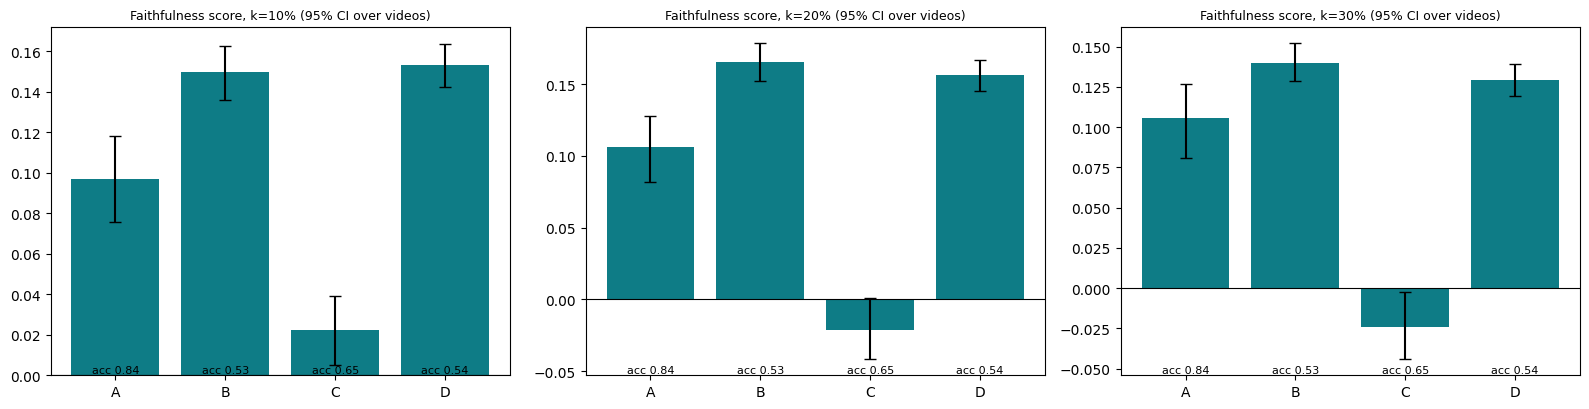

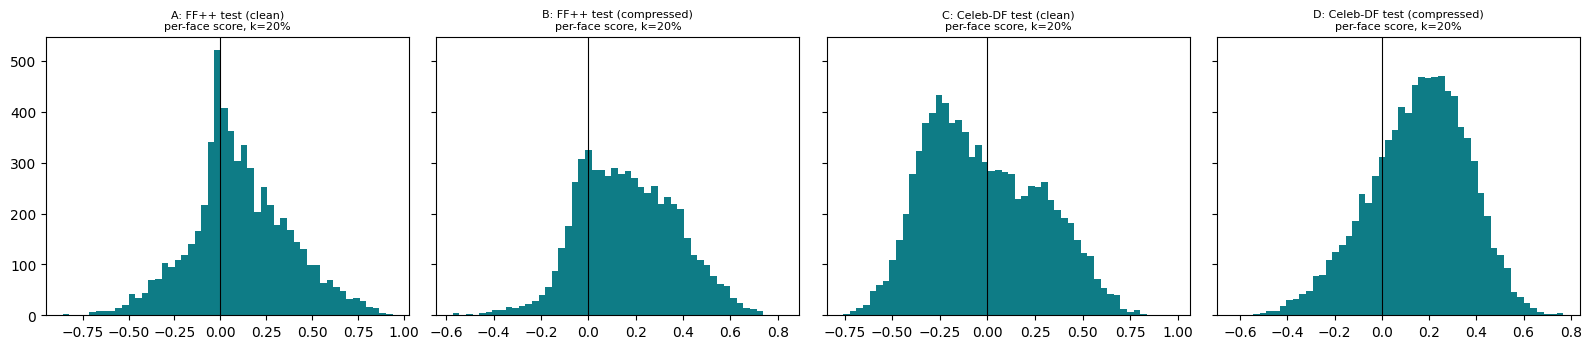

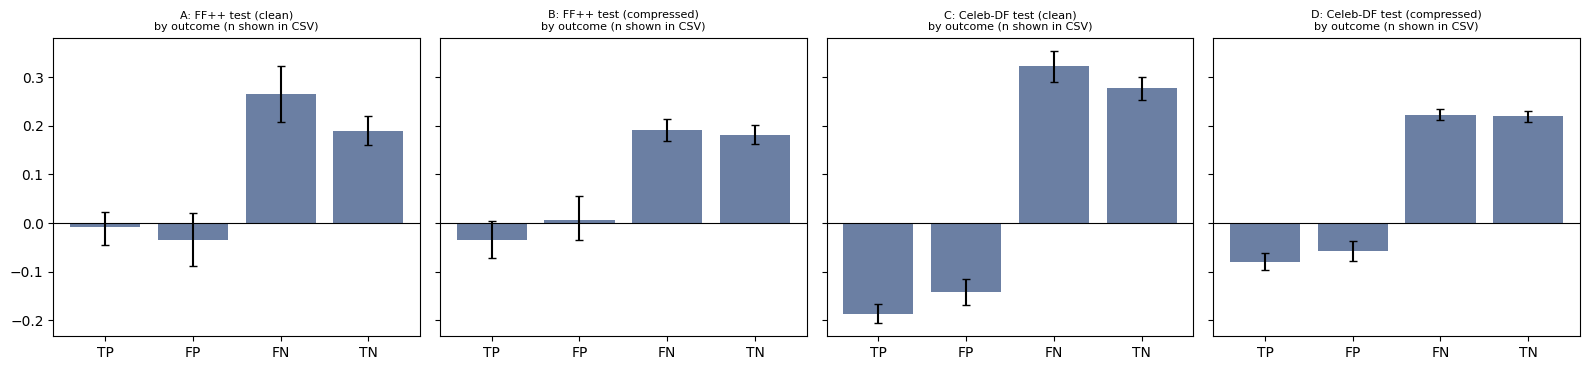

In [12]:
# ============================================================
# FIGURES
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, kk in zip(axes, KS):
    s = fsum[(fsum["metric"] == "faithfulness") & (fsum["k"] == kk) & (fsum["group"] == "ALL") & (fsum["fill"] == "zero")].set_index("cond").loc[list("ABCD")]
    ax.bar(list("ABCD"), s["mean"], yerr=[s["mean"] - s["ci_lo"], s["ci_hi"] - s["mean"]], capsize=4, color="#0E7C86")
    ax.axhline(0, color="k", lw=0.8); ax.set_title(f"Faithfulness score, k={kk}% (95% CI over videos)", fontsize=9)
    for i, (c_, r_) in enumerate(s.iterrows()): ax.text(i, ax.get_ylim()[0], f"acc {r_['accuracy']:.2f}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "faithfulness_by_condition.png"), dpi=130); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, k in zip(axes, "ABCD"):
    ax.hist(faith[k][f"faith_{K_PRIMARY}"], bins=50, color="#0E7C86"); ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{cond[k]['name']}\nper-face score, k={K_PRIMARY}%", fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "faithfulness_hist.png"), dpi=130); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, k in zip(axes, "ABCD"):
    s = fsum[(fsum["metric"] == "faithfulness") & (fsum["k"] == K_PRIMARY) & (fsum["fill"] == "zero") & (fsum["group"].isin(["TP", "FP", "FN", "TN"]))].query("cond == @k")
    ax.bar(s["group"], s["mean"], yerr=[s["mean"] - s["ci_lo"], s["ci_hi"] - s["mean"]], capsize=3, color="#6B7FA3")
    ax.axhline(0, color="k", lw=0.8); ax.set_title(f"{cond[k]['name']}\nby outcome (n shown in CSV)", fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "faithfulness_by_outcome.png"), dpi=130); plt.show()

In [13]:
# ============================================================
# CHECKS + METADATA
# ============================================================
checks = []
for k in "ABCD":
    d = faith[k]
    checks += [{"check": f"{k}: one score per face", "value": len(d), "limit": len(cond[k]["df"]), "pass": len(d) == len(cond[k]["df"]) and d["face_id"].is_unique},
               {"check": f"{k}: no NaN scores", "value": int(d[[c for c in d.columns if c.startswith(("faith_", "d_cam_", "d_rand_", "d_low_"))]].isna().sum().sum()), "limit": 0,
                "pass": not d[[c for c in d.columns if c.startswith("faith_")]].isna().any().any()},
               {"check": f"{k}: deletion check (top hurts more than lowest, k={K_PRIMARY})", "value": round(float(deletion.query("cond == @k and k == @K_PRIMARY")["top_minus_low"].iloc[0]), 4),
                "limit": "> 0", "pass": bool(deletion.query("cond == @k and k == @K_PRIMARY")["deletion_check_ok"].iloc[0])},
               {"check": f"{k}: blur-fill subset scored", "value": len(faith_blur[k]), "limit": min(BLUR_SUBSET, len(cond[k]["df"])), "pass": len(faith_blur[k]) == min(BLUR_SUBSET, len(cond[k]["df"]))}]
checks = pd.DataFrame(checks); checks.to_csv(os.path.join(OUT, "faithfulness_checks.csv"), index=False)
print(checks.to_string(index=False))
json.dump({"created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "model_sha256": sha256(best_pt), "manifest_sha256": meta["manifest_sha256"],
           "threshold": THRESHOLD, "ks": list(KS), "k_primary": K_PRIMARY, "R": R, "seed": SEED, "fill_primary": "zero (mid-grey in normalised space)",
           "fill_second": f"blur (gaussian k=61, sigma=20) on {BLUR_SUBSET} faces per condition", "target_class": "predicted class from cams_*.npz target",
           "probability": "p_pred = probability of the predicted class, fp16 autocast like Step 2.5", "mask_resolution": "10x10 Grad-CAM cells, nearest upsampling",
           "confident_threshold": CONF_MIN, "bootstrap": f"{N_BOOT} resamples of videos", "torch": torch.__version__, "timm": timm.__version__},
          open(os.path.join(OUT, "faithfulness_meta.json"), "w"), indent=2)
print("\nsaved:", sorted(os.listdir(OUT)))
bad = checks[(~checks["pass"]) & (~checks["check"].str.contains("deletion"))]
assert bad.empty, "AN INTEGRITY CHECK FAILED:\n" + bad.to_string()
if (~checks["pass"]).any():
    print("WARNING: the deletion check failed for some conditions. Plan says something may be wrong: inspect deletion_check.csv before interpreting scores.")
print("Done. Next: Step 2.8 stability. Do NOT retrain or change the threshold.")

                                               check     value limit  pass
                               A: one score per face 5883.0000  5883  True
                                    A: no NaN scores    0.0000     0  True
A: deletion check (top hurts more than lowest, k=20)    0.4139   > 0  True
                          A: blur-fill subset scored 1000.0000  1000  True
                               B: one score per face 5883.0000  5883  True
                                    B: no NaN scores    0.0000     0  True
B: deletion check (top hurts more than lowest, k=20)    0.3734   > 0  True
                          B: blur-fill subset scored 1000.0000  1000  True
                               C: one score per face 8763.0000  8763  True
                                    C: no NaN scores    0.0000     0  True
C: deletion check (top hurts more than lowest, k=20)    0.3384   > 0  True
                          C: blur-fill subset scored 1000.0000  1000  True
                         